# Partition uncertainties in projections of impacts

1. Of just mean estimates
2. With regression uncertainties
3. Bootstrapped over number of runs (maybe spin that off into a 4b?)
4. TODO: Without MERRA2

For different sets of runs: 
- a "balanced panel" of GCMs / runs
- all available runs at GWL 2n

In [1]:
import xarray as xr
import xagg as xa
import numpy as np
import pandas as pd
import geopandas as gpd
import os
import re
import glob
import zarr
import warnings
from tqdm.notebook import tqdm
from dask.diagnostics import ProgressBar
from matplotlib import colors as mcolors

import distributed

from funcs_support import get_filepaths,get_params,utility_save
from funcs_readregs import coeffs_mortality, coeffs_gdppc
from funcs_processing import calc_uncerts
from funcs_plot import plot_map, vals_to_color_triangle

dir_list = get_params()

In [2]:
from distributed import Client

# Start dask client 
# (playing around with workers, threads for efficiency)
client = Client(n_workers=6,
    threads_per_worker=3,
    processes=True,
    memory_limit="8GB")
display(client)

/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/distributed/node.py:188: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 39675 instead
  warnings.warn(


Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc/proxy/39675/status,
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc/proxy/39675/status,Workers: 6
Total threads: 18,Total memory: 44.70 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:35155,Workers: 0
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc/proxy/39675/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:43345,Total threads: 3
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc/proxy/42003/status,Memory: 7.45 GiB
Nanny: tcp://127.0.0.1:38635,


2026-03-18 11:10:37,507 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle cd831796a83bfeb366adbc3a7c4efcb8 initialized by task ('rechunk-merge-rechunk-transfer-8003caa73aad2232f99c0eb4d5923a62', 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 105, 0) executed on worker tcp://127.0.0.1:42737
2026-03-18 11:11:13,546 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle cd831796a83bfeb366adbc3a7c4efcb8 deactivated due to stimulus 'task-finished-1773853873.546296'
2026-03-18 11:13:16,985 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle 35e0692013ab2c1536a47f09f2e1c21c initialized by task ('rechunk-merge-rechunk-transfer-88f7e49c00db83243a1bca54fac1c1bf', 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0) executed on worker tcp://127.0.0.1:39395
2026-03-18 11:13:17,343 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle 35e0692013ab2c1536a47f09f2e1c21c deactivated due to stimulus 'task-finished-1773853997.343158'
2026-03-18 11:13:24,029 - distributed.shuffle._sched

## Climate uncertainty partitioning

In [200]:
params_proc = {'mortality':{'varname':'tassumpoly','geo_typ':'impact-regions','popwght':False},
               'gdppc':{'varname':'tassumpoly','geo_typ':'adm1','popwght':True},
              'payroll':{'varname':'tasmaxbinF','geo_typ':'adm2-us','popwght':True}}

#params_proc = {'payroll':{'varname':'tasmaxbinF','geo_typ':'adm2-us','popwght':True}}


In [201]:
overwrite = True
for proc in params_proc:
    output_fn = f'{dir_list['proc']}uncert_parts/uncert_parts_{proc}.zarr'
    if overwrite or (not os.path.exists(output_fn)):
        #---------------------------
        # Setup
        #---------------------------
        # Load impacts projections
        fns = np.sort(glob.glob(f'{dir_list['proc']}impact_projs/{proc}/d{proc}*.zarr'))
        def load_impact(fn):
            ds_tmp = xr.open_zarr(fn,consolidated=False)
            ds_tmp = ds_tmp.set_coords('locid') # Should be coordinate, instead of concatenated variable
            ds_tmp = ds_tmp.assign_coords({'model':(('idv'),[re.split(r'\_',re.split(r'\/',fn)[-1])[2]]*ds_tmp.sizes['idv'])})
        
            ds_tmp['exprun'] = ds_tmp['experiment']+ds_tmp['run']
            ds_tmp = ds_tmp.reset_index('idv')
            ds_tmp = ds_tmp.set_index(idv = ['model','exprun'])
            return ds_tmp
        
        with warnings.catch_warnings():
            # Silence zarr warnings related to the /.done flags used
            warnings.filterwarnings('ignore')
            dss = xr.concat([load_impact(fn) for fn in fns],
                        dim='idv',join='outer')
        
        
        dss = dss.chunk({'poly_idx':50,'idv':-1,'proj_base':-1,'gwl':-1})

        # Save temporary rechunked file to make dask graphing more stable
        tmp_fn = dir_list['proc']+'tmp/uncert_rechunk_cache_tmp.zarr'
        utility_save(dss.reset_index('idv').drop_encoding(),tmp_fn,zarr_mode = 'w')
        dss = xr.open_zarr(tmp_fn).set_index(idv = ['model','exprun'])
        
        # Figure out how many BCD-ME members reach a given GWL
        gwl_counter = dss.maxgwl.load().reset_index('idv').groupby(['model','maxgwl']).count()
        gwl_counter = gwl_counter.sel(maxgwl = gwl_counter.maxgwl.values[::-1]).cumsum('maxgwl')
        #print(gwl_counter)
        
        uncerts_all = []
        #---------------------------
        # Uncertainty partitioning over all runs
        #---------------------------
        dss_tmp = dss.unstack('idv')['d'+proc]
        dss_tmp = dss_tmp.chunk({'model':-1,'exprun':-1})
        
        # Calculate uncertainty partitioning
        with warnings.catch_warnings():
            # Ignoring chunk increase warnings and divide by 0s in uncertainty 
            # partitioning (happens over ocean, e.g.)
            warnings.filterwarnings('ignore')
            uncerts = xr.map_blocks(calc_uncerts,dss_tmp).compute()
        
        uncerts = uncerts.expand_dims({'sample':['allruns']})
        
        uncerts_all.append(uncerts)
        
        #---------------------------
        # Uncertainty partitioning over a balanced panel up to GWL 3
        #---------------------------
        max_gwl = 3
        if proc == 'payroll':
            nruns = 10
        else:
            nruns = 13
        
        gwlmods = gwl_counter.sel(maxgwl=3)
        proc_mods = gwlmods.isel(model = gwlmods>=nruns).model.values
        
        dss_tmp = dss.isel(idv = dss.maxgwl>=max_gwl).groupby('model').map(lambda x: x.isel(idv=slice(0, nruns)))
        dss_tmp = dss_tmp.isel(idv=[m in proc_mods for m in dss_tmp.model.values]).chunk({'idv':-1})
        dss_tmp = dss_tmp.unstack('idv')['d'+proc]
        dss_tmp = dss_tmp.chunk({'model':-1,'exprun':-1})
        
        with warnings.catch_warnings():
            # Ignoring chunk increase warnings and divide by 0s in uncertainty 
            # partitioning (happens over ocean, e.g.)
            warnings.filterwarnings('ignore')
            uncerts = xr.map_blocks(calc_uncerts,dss_tmp).compute()
        
        uncerts = uncerts.expand_dims({'sample':[f'{str(nruns)}runs{str(dss_tmp.sizes['model'])}mods']})
        
        uncerts_all.append(uncerts)

        #---------------------------
        # Uncertainty partitioning over a balanced panel up to GWL 3
        # without MERRA2
        #---------------------------
        max_gwl = 3
        if proc == 'payroll':
            nruns = 10
        else:
            nruns = 13
        
        gwlmods = gwl_counter.sel(maxgwl=3)
        proc_mods = gwlmods.isel(model = gwlmods>=nruns).model.values
        
        dss_tmp = dss.isel(idv = dss.maxgwl>=max_gwl).groupby('model').map(lambda x: x.isel(idv=slice(0, nruns)))
        dss_tmp = dss_tmp.sel(proj_base = [pb for pb in dss_tmp.proj_base.values if pb != 'MERRA2'])
        dss_tmp = dss_tmp.isel(idv=[m in proc_mods for m in dss_tmp.model.values]).chunk({'idv':-1})
        dss_tmp = dss_tmp.unstack('idv')['d'+proc]
        dss_tmp = dss_tmp.chunk({'model':-1,'exprun':-1})
        
        with warnings.catch_warnings():
            # Ignoring chunk increase warnings and divide by 0s in uncertainty 
            # partitioning (happens over ocean, e.g.)
            warnings.filterwarnings('ignore')
            uncerts = xr.map_blocks(calc_uncerts,dss_tmp).compute()
        
        uncerts = uncerts.expand_dims({'sample':[f'{str(nruns)}runs{str(dss_tmp.sizes['model'])}mods_noMERRA2']})
        
        uncerts_all.append(uncerts)
        
        #---------------------------
        # Export
        #---------------------------
        # Concatenate into single ds
        uncerts_all = xr.concat(uncerts_all,dim='sample')
        uncerts_all = uncerts_all.where(uncerts_all.sum('typ')>0)
        
        # Export
        uncerts_all.attrs = {'SOURCE':'4_partition_uncertainty.ipynb',
                             'DESCRIPTION':f'Uncertainty partitioning of projections of {proc} between model, internal, and reanalysis sources'}
        
        utility_save(uncerts_all,output_fn,zarr_mode = 'w')

        os.system('rm -rf '+tmp_fn)
        print('Temporary file '+tmp_fn+' removed.')
    else:
        print(output_fn+' exists!')
    


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=9, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=13, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change wit

/glade/derecho/scratch/schwarzwald/impact_uncertainty/tmp/uncert_rechunk_cache_tmp.zarr saved!


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/xarray/core/nputils.py:242: RuntimeWarning: Degrees of freedom <= 0 for slice.
  result = getattr(npmodule, name)(values, axis=axis, **kwargs)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/xarray/core/nputils.py:242: RuntimeWarning: Degrees of freedom <= 0 for slice.
  result = getattr(npmodule, name)(values, axis=axis, **kwargs)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/xarray/core/nputils.py:242: RuntimeWarning: Degrees of freedom <= 0 for slice.
  result = getattr(npmodule, name)(values, axis=axis, **kwargs)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/xarray/core/nputils.py:242: RuntimeWarning: Degrees of freedom <= 0 for slice.
  result = getattr(npmodule, name)(values, axis=axis, **kwargs)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/xarray/core/nputils.py:

/glade/derecho/scratch/schwarzwald/impact_uncertainty/uncert_parts/uncert_parts_mortality.zarr removed to allow overwrite!


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/api/asynchronous.py:247: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


...

/glade/derecho/scratch/schwarzwald/impact_uncertainty/tmp/uncert_rechunk_cache_tmp.zarr saved!


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/xarray/core/nputils.py:242: RuntimeWarning: Degrees of freedom <= 0 for slice.
  result = getattr(npmodule, name)(values, axis=axis, **kwargs)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/xarray/core/nputils.py:242: RuntimeWarning: Degrees of freedom <= 0 for slice.
  result = getattr(npmodule, name)(values, axis=axis, **kwargs)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/xarray/core/nputils.py:242: RuntimeWarning: Degrees of freedom <= 0 for slice.
  result = getattr(npmodule, name)(values, axis=axis, **kwargs)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/xarray/core/nputils.py:242: RuntimeWarning: Degrees of freedom <= 0 for slice.
  result = getattr(npmodule, name)(values, axis=axis, **kwargs)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/xarray/core/nputils.py:

/glade/derecho/scratch/schwarzwald/impact_uncertainty/uncert_parts/uncert_parts_payroll.zarr removed to allow overwrite!


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/api/asynchronous.py:247: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


/glade/derecho/scratch/schwarzwald/impact_uncertainty/uncert_parts/uncert_parts_payroll.zarr saved!
Temporary file /glade/derecho/scratch/schwarzwald/impact_uncertainty/tmp/uncert_rechunk_cache_tmp.zarr removed.


In [197]:
uncerts_all.sample

<xarray.DataArray 'sample' (sample: 3)> Size: 24B
array(['allruns', '10runs7mods', '10runs7mods_noMERRA2'], dtype=object)
Coordinates:
  * sample   (sample) object 24B 'allruns' '10runs7mods' '10runs7mods_noMERRA2'

In [191]:
dss.isel(idv=0,**hps).dpayroll.load()

<xarray.DataArray 'dpayroll' (gwl: 8)> Size: 64B
array([nan, nan, nan, nan, nan, nan, nan, nan])
Coordinates: (12/14)
  * gwl         (gwl) float64 64B 0.61 1.0 1.5 2.0 2.5 3.0 3.5 4.0
    experiment  <U11 44B 'ssp245'
    locid       StringDType() 16B ''
    maxgwl      float64 8B 4.0
    obstreat    <U3 12B 'sep'
    poly_idx    int64 8B 1000
    ...          ...
    run         <U9 36B 'r10i1p1f1'
    timeframe   <U9 36B '1986-2008'
    weighting   <U3 12B 'pop'
    idv         object 8B ('ACCESS-ESM1-5', 'ssp245r10i1p1f1')
    model       <U13 52B 'ACCESS-ESM1-5'
    exprun      <U20 80B 'ssp245r10i1p1f1'

In [170]:
with warnings.catch_warnings():
    # Silence zarr warnings related to the /.done flags used
    warnings.filterwarnings('ignore')
    dss = xr.concat([load_impact(fn) for fn in fns],
                dim='idv',join='outer')
dss = dss.chunk({'poly_idx':50,'idv':-1,'proj_base':-1,'gwl':-1})

# Save temporary rechunked file to make dask graphing more stable
tmp_fn = dir_list['proc']+'tmp/uncert_rechunk_cache_tmp.zarr'
utility_save(dss.reset_index('idv').drop_encoding(),tmp_fn,zarr_mode = 'w')
dss = xr.open_zarr(tmp_fn).set_index(idv = ['model','exprun'])


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=9, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=13, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change wit

/glade/derecho/scratch/schwarzwald/impact_uncertainty/tmp/uncert_rechunk_cache_tmp.zarr saved!


In [141]:
max_gwl = 3
nruns = 13

gwlmods = gwl_counter.sel(maxgwl=3)
proc_mods = gwlmods.isel(model = gwlmods>=nruns).model.values

dss_tmp = dss.isel(idv = dss.maxgwl>=max_gwl).groupby('model').map(lambda x: x.isel(idv=slice(0, nruns)))
dss_tmp = dss_tmp.isel(idv=[m in proc_mods for m in dss_tmp.model.values]).chunk({'idv':-1})
dss_tmp = dss_tmp.unstack('idv')['d'+proc]
dss_tmp = dss_tmp.chunk({'model':-1,'exprun':-1})

In [173]:
# Figure out how many BCD-ME members reach a given GWL
gwl_counter = dss.maxgwl.load().reset_index('idv').groupby(['model','maxgwl']).count()
gwl_counter = gwl_counter.sel(maxgwl = gwl_counter.maxgwl.values[::-1]).cumsum('maxgwl')
#print(gwl_counter)

uncerts_all = []

In [179]:
(~np.isnan(dss.sel(gwl=3).isel(resolution=0,timeframe=0,obstreat=0,weighting=0,poly_idx=1000).dpayroll.load())).sum('idv')

<xarray.DataArray 'dpayroll' (proj_base: 4)> Size: 32B
array([137, 137, 137, 137])
Coordinates:
  * proj_base   (proj_base) <U6 96B 'ERA5' 'GMFD' 'JRA-3Q' 'MERRA2'
    gwl         float64 8B 3.0
    locid       StringDType() 16B '29121'
    obstreat    <U3 12B 'sep'
    poly_idx    int64 8B 1000
    resolution  <U6 24B '025deg'
    timeframe   <U9 36B '1986-2008'
    weighting   <U3 12B 'pop'

In [174]:
gwl_counter

<xarray.DataArray 'maxgwl' (model: 11, maxgwl: 6)> Size: 528B
array([[25., 25., 25., 25., 25., 25.],
       [15., 15., 16., 18., 18., 18.],
       [37., 38., 39., 39., 41., 41.],
       [87., 87., 87., 87., 87., 87.],
       [21., 32., 35., 35., 35., 35.],
       [ 9., 14., 14., 14., 14., 14.],
       [ 0.,  0.,  7., 10., 10., 10.],
       [18., 28., 28., 28., 28., 28.],
       [ 0.,  0., 48., 51., 51., 63.],
       [ 0., 16., 20., 30., 30., 30.],
       [ 0., 11., 14., 16., 16., 16.]])
Coordinates:
  * model    (model) object 88B 'ACCESS-ESM1-5' 'CNRM-CM6-1' ... 'MRI-ESM2-0'
  * maxgwl   (maxgwl) float64 48B 4.0 3.5 3.0 2.5 2.0 1.5

In [145]:
.dss.isel(idv = dss.maxgwl>=max_gwl)

<xarray.Dataset> Size: 2GB
Dimensions:     (proj_base: 4, resolution: 2, timeframe: 2, obstreat: 1,
                 weighting: 2, poly_idx: 3141, idv: 367, gwl: 8)
Coordinates: (12/14)
  * proj_base   (proj_base) <U6 96B 'ERA5' 'GMFD' 'JRA-3Q' 'MERRA2'
  * resolution  (resolution) object 16B '025deg' '1deg'
  * timeframe   (timeframe) object 16B '1986-2008' 'ALLYEARS'
  * obstreat    (obstreat) object 8B 'sep'
  * weighting   (weighting) object 16B 'pop' 'raw'
  * poly_idx    (poly_idx) int64 25kB 0 1 2 3 4 5 ... 3136 3137 3138 3139 3140
    ...          ...
    experiment  (idv) <U11 16kB 'ssp245' 'ssp245' 'ssp245' ... 'ssp585' 'ssp585'
    maxgwl      (idv) float64 3kB 4.0 4.0 4.0 4.0 4.0 ... 3.5 3.5 3.5 3.5 3.5
    run         (idv) <U9 13kB 'r10i1p1f1' 'r11i1p1f1' ... 'r4i1p1f1' 'r5i1p1f1'
  * model       (idv) <U13 19kB 'ACCESS-ESM1-5' 'ACCESS-ESM1-5' ... 'MRI-ESM2-0'
  * exprun      (idv) <U20 29kB 'ssp245r10i1p1f1' ... 'ssp585r5i1p1f1'
  * gwl         (gwl) float64 64B 0.61 1.0 1.5 2.0 2.5 3.0 3.5 4.0
Data variables:
    dpayroll    (proj_base, resolution, timeframe, obstreat, weighting, poly_idx, idv, gwl) float64 2GB dask.array<chunksize=(4, 2, 2, 1, 2, 50, 367, 8), meta=np.ndarray>
Attributes:
    SOURCE:        project_impacts.ipynb
    DESCRIPTION:   changes in payroll, at the adm2-us level
    pop_weighted:  True

In [64]:
dss = dss.chunk({'poly_idx':50,'idv':-1,'proj_base':-1,'gwl':-1})

# Save temporary rechunked file to make dask graphing more stable
tmp_fn = dir_list['proc']+'tmp/uncert_rechunk_cache_tmp.zarr'
utility_save(dss.reset_index('idv').drop_encoding(),tmp_fn,zarr_mode = 'w')
dss = xr.open_zarr(tmp_fn).set_index(idv = ['model','exprun'])


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=9, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=13, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change wit

/glade/derecho/scratch/schwarzwald/impact_uncertainty/tmp/uncert_rechunk_cache_tmp.zarr saved!


In [68]:
# Figure out how many BCD-ME members reach a given GWL
gwl_counter = dss.maxgwl.load().reset_index('idv').groupby(['model','maxgwl']).count()
gwl_counter = gwl_counter.sel(maxgwl = gwl_counter.maxgwl.values[::-1]).cumsum('maxgwl')
#print(gwl_counter)

uncerts_all = []
#---------------------------
# Uncertainty partitioning over all runs
#---------------------------
dss_tmp = dss.unstack('idv')['d'+proc]
dss_tmp = dss_tmp.chunk({'model':-1,'exprun':-1})

In [74]:
a = dss_tmp.sel(resolution='025deg',timeframe='1986-2008',obstreat='sep',weighting='pop')
a = a.load()

In [98]:
max_gwl = 3
nruns = 13

gwlmods = gwl_counter.sel(maxgwl=3)
proc_mods = gwlmods.isel(model = gwlmods>=nruns).model.values

dss_tmp = dss.isel(idv = dss.maxgwl>=max_gwl).groupby('model').map(lambda x: x.isel(idv=slice(0, nruns)))
dss_tmp = dss_tmp.isel(idv=[m in proc_mods for m in dss_tmp.model.values]).chunk({'idv':-1})
dss_tmp = dss_tmp.unstack('idv')['d'+proc]
dss_tmp = dss_tmp.chunk({'model':-1,'exprun':-1})

with warnings.catch_warnings():
    # Ignoring chunk increase warnings and divide by 0s in uncertainty 
    # partitioning (happens over ocean, e.g.)
    warnings.filterwarnings('ignore')
    uncerts = xr.map_blocks(calc_uncerts,dss_tmp).compute()

uncerts = uncerts.expand_dims({'sample':[f'{str(nruns)}runs{str(dss_tmp.sizes['model'])}mods']})

/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/xarray/core/nputils.py:242: RuntimeWarning: Degrees of freedom <= 0 for slice.
  result = getattr(npmodule, name)(values, axis=axis, **kwargs)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/xarray/core/nputils.py:242: RuntimeWarning: Degrees of freedom <= 0 for slice.
  result = getattr(npmodule, name)(values, axis=axis, **kwargs)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/xarray/core/nputils.py:242: RuntimeWarning: Degrees of freedom <= 0 for slice.
  result = getattr(npmodule, name)(values, axis=axis, **kwargs)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/xarray/core/nputils.py:242: RuntimeWarning: Degrees of freedom <= 0 for slice.
  result = getattr(npmodule, name)(values, axis=axis, **kwargs)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/xarray/core/nputils.py:

/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/xarray/core/nputils.py:242: RuntimeWarning: Degrees of freedom <= 0 for slice.
  result = getattr(npmodule, name)(values, axis=axis, **kwargs)


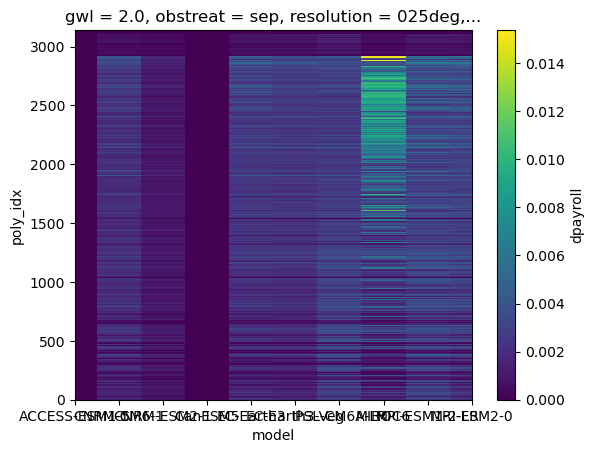

In [123]:
np.sqrt(a.var('proj_base').mean('exprun').reset_index(['poly_idx','model'])).plot()